<a href="https://colab.research.google.com/github/GehadHelmy/github_SNA/blob/main/Project_SNA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Libraries**

In [ ]:
import pandas as pd
import numpy as np
import json
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import networkx.algorithms.community as nx_comm
from matplotlib.collections import LineCollection
from sklearn.metrics import normalized_mutual_info_score
from scipy.sparse import csr_matrix

## **Dataset Understanding**

In [ ]:
edges_df = pd.read_csv("musae_git_edges.csv")
target_df = pd.read_csv("musae_git_target.csv")
with open("musae_git_features.json", "r") as file:
    features_data = json.load(file)

In [ ]:
print("Edges Shape:", edges_df.shape)
print("Target Shape:", target_df.shape)
print("Number of Feature Records:", len(features_data))

Edges Shape: (289003, 2)
Target Shape: (37700, 3)
Number of Feature Records: 37700


In [ ]:
print("Edges:")
display(edges_df.head())
print("Target:")
display(target_df.head())

Edges:


,id_1,id_2
0,0,23977
1,1,34526
2,1,2370
3,1,14683
4,1,29982


Target:


,id,name,ml_target
0,0,Eiryyy,0
1,1,shawflying,0
2,2,JpMCarrilho,1
3,3,SuhwanCha,0
4,4,sunilangadi2,1


In [ ]:
print(edges_df.columns)
print(target_df.columns)

Index(['id_1', 'id_2'], dtype='object')
Index(['id', 'name', 'ml_target'], dtype='object')


In [ ]:
for i, (node_id, features) in enumerate(features_data.items()):
    print(node_id, features)
    if i == 4:
        break

0 [1574, 3773, 3571, 2672, 2478, 2534, 3129, 3077, 1171, 2045, 1539, 902, 1532, 2472, 1122, 2480, 3098, 2115, 1578]
1 [1193, 376, 73, 290, 3129, 1852, 3077, 1171, 1022, 2045, 536, 2040, 1533, 1532, 2472, 673, 798]
2 [1574, 3773, 925, 1728, 2815, 2963, 3077, 364, 1171, 536, 1867, 2472, 1122, 2532, 664, 28, 3311, 1768, 869]
3 [3964, 3773, 4003, 928, 1852, 3077, 364, 1022, 3763, 2045, 3859, 3771, 234, 664, 703]
4 [1929, 3773, 1793, 3511, 1290, 3129, 3077, 364, 1171, 1022, 2045, 536, 1119, 91, 1532, 3771, 1122, 703, 1001]


## **Data Preprocessing & Cleaning**

In [ ]:
print("Edges Missing Values:")
print(edges_df.isnull().sum())
print("\nTarget Missing Values:")
print(target_df.isnull().sum())

Edges Missing Values:
id_1    0
id_2    0
dtype: int64

Target Missing Values:
id           0
name         0
ml_target    0
dtype: int64


In [ ]:
edges_df["source"] = edges_df["id_1"].astype(int)

edges_df["target"] = edges_df["id_2"].astype(int)

edges_df["source_id"] = edges_df[["source", "target"]].min(axis=1)

edges_df["target_id"] = edges_df[["source", "target"]].max(axis=1)

print("Original Edges:", len(edges_df))
edges_df = edges_df.drop_duplicates(
    subset=["source_id", "target_id"])
edges_df = edges_df[["source_id", "target_id"]]
print("After Removing Duplicates:", len(edges_df))

Original Edges: 289003
After Removing Duplicates: 289003


In [ ]:
self_loops = edges_df[
    edges_df["source_id"] == edges_df["target_id"]]
print("Number of Self Loops:", len(self_loops))

Number of Self Loops: 0


In [ ]:
print("Duplicate Developer IDs:",target_df["id"].duplicated().sum())

Duplicate Developer IDs: 0


## **Graph Construction**

In [ ]:
feature_nodes = set(map(int, features_data.keys()))
len(feature_nodes)

37700

In [ ]:
G = nx.Graph()
G.add_nodes_from(feature_nodes)
G.add_edges_from(
    edges_df[["source_id", "target_id"]].itertuples(
        index=False,
        name=None
    ))
print("Number of Nodes:", G.number_of_nodes())
print("Number of Edges:", G.number_of_edges())

Number of Nodes: 37700
Number of Edges: 289003


### **Edge List**

In [ ]:
edge_list = list(G.edges())
print(edge_list[:10])

[(0, 23977), (1, 34526), (1, 2370), (1, 14683), (1, 29982), (1, 21142), (1, 20363), (1, 23830), (1, 34035), (2, 3812)]


In [ ]:
edge_list_df = pd.DataFrame(
    edge_list,
    columns=["Source", "Target"])
edge_list_df.to_csv("edge_list.csv", index=False)
edge_list_df.head()

,Source,Target
0,0,23977
1,1,34526
2,1,2370
3,1,14683
4,1,29982


### **Adjacency List**

In [ ]:
adjacency_list = nx.to_dict_of_lists(G)
for node, neighbors in list(adjacency_list.items())[:5]:
    print(node, ":", neighbors)

0 : [23977]
1 : [34526, 2370, 14683, 29982, 21142, 20363, 23830, 34035]
2 : [3812]
3 : [4950, 18029, 3358, 34935, 5916]
4 : [2865, 9342]


In [ ]:
with open("adjacency_list.json", "w") as file:
    json.dump(adjacency_list, file)

### **Adjacency Matrix**

In [ ]:
from scipy.sparse import csr_matrix
A = nx.to_scipy_sparse_array(
    G,
    format="csr",
    dtype=np.int8)
print("Matrix Shape:", A.shape)
print("Number of Connections:", A.nnz)
print("Matrix Type:", type(A))

Matrix Shape: (37700, 37700)
Number of Connections: 578006
Matrix Type: <class 'scipy.sparse._csr.csr_array'>


In [114]:
import graphistry
from google.colab import userdata

username = userdata.get("GRAPHISTRY_USERNAME")
password = userdata.get("GRAPHISTRY_PASSWORD")

graphistry.register(
    api=3,
    username=username,
    password=password
)

g = graphistry.edges(
    edges_df,
    source="source_id",
    destination="target_id"
)

g2 = g.scene_settings(
    show_arrows=False,
    point_size=2.0,
    edge_curvature=0.0,
    point_opacity=1.0,
    edge_opacity=0.47
)

g2.plot()

In [ ]:
graph_url = g2.plot(render=False)
print(graph_url)

## **Degree Analysis & Network Properties**

### **Node Degree**

In [ ]:
degree_dict = dict(G.degree())

degree_df = pd.DataFrame({
    "developer_id": list(degree_dict.keys()),
    "degree": list(degree_dict.values())
})

degree_df.head(10)

In [ ]:
degree_df['degree'].describe()

### **Average Degree**

In [ ]:
average_degree = sum(dict(G.degree()).values()) / G.number_of_nodes()

print("Average Degree:", round(average_degree, 4))

### **Degree Distribution**

In [ ]:
degrees = [degree for node, degree in G.degree()]

degree_distribution = (
    pd.Series(degrees)
    .value_counts(normalize=True)
    .sort_index()
)

plt.figure(figsize=(10, 6))

plt.bar(
    degree_distribution.index,
    degree_distribution.values,
    color="steelblue",
    edgecolor="black"
)

plt.title("Degree Distribution of GitHub Developers")
plt.xlabel("Degree (k)")
plt.ylabel("P(k) = Nk / N")
plt.grid(axis="y", alpha=0.3)
plt.xlim(0, 100)

plt.show()

### **Top 10 Developers by Degree**

In [ ]:
top_10 = degree_df.sort_values(
    by="degree",
    ascending=False
).head(10)

top_10 = top_10.merge(
    target_df[["id", "name", "ml_target"]],
    left_on="developer_id",
    right_on="id",
    how="left"
)

top_10 = top_10[
    ["developer_id", "name", "degree", "ml_target"]
]

display(top_10)

In [ ]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_10,
    x="degree",
    y="name",
    color="steelblue"
)

plt.title("Top 10 GitHub Developers by Degree")
plt.xlabel("Number of Connections")
plt.ylabel("Developer")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### **Clustering Coefficient**

In [ ]:
clustering_dict = nx.clustering(G)

clustering_df = pd.DataFrame({
    "developer_id": list(clustering_dict.keys()),
    "clustering_coefficient": list(clustering_dict.values())
})

display(clustering_df.head(10))

### **Highest 10 Clustering Coefficients**

In [ ]:
clustering_df = clustering_df.merge(
    target_df[["id", "name"]],
    left_on="developer_id",
    right_on="id",
    how="left"
)

clustering_df = clustering_df.drop(columns=["id"])


In [ ]:
top_10_clustering = clustering_df.sort_values(
    by="clustering_coefficient",
    ascending=False
).head(10)

display(top_10_clustering)

### **Lowest 10 Clustering Coefficients**

In [ ]:
bottom_10_clustering = clustering_df.sort_values(
    by="clustering_coefficient",
    ascending=True
).head(10)

display(bottom_10_clustering)

### **Average Clustering Coefficient**

In [ ]:
average_clustering = nx.average_clustering(G)

print("Average Clustering Coefficient:", round(average_clustering, 4))

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    clustering_df["clustering_coefficient"],
    bins=30,
    color="steelblue",
    edgecolor="black"
)

plt.title("Clustering Coefficient Distribution")
plt.xlabel("Clustering Coefficient")
plt.ylabel("Number of Developers")
plt.grid(axis="y", alpha=0.3)

plt.show()

## **Connectivity & Graph Structure**

### **Connected Components**

In [ ]:
connected_components = list(nx.connected_components(G))
num_components = len(connected_components)

print("Number of Connected Components:", num_components)

In [ ]:
component_sizes = [len(component) for component in connected_components]

component_sizes_df = pd.DataFrame({
    "component_id": range(1, num_components + 1),
    "number_of_developers": component_sizes
})

component_sizes_df

### **Special Graphs**

In [ ]:
num_nodes = G.number_of_nodes()
num_edges = G.number_of_edges()

is_complete = num_edges == (num_nodes * (num_nodes - 1)) / 2

degrees = [degree for node, degree in G.degree()]
is_regular = len(set(degrees)) == 1

is_tree = nx.is_tree(G)

is_bipartite = nx.is_bipartite(G)

special_graphs_df = pd.DataFrame({
    "Graph Property": [
        "Complete Graph",
        "Regular Graph",
        "Tree",
        "Bipartite Graph"
    ],
    "Result": [
        is_complete,
        is_regular,
        is_tree,
        is_bipartite
    ]
})

display(special_graphs_df)

# **Centrality Measures**

In [115]:
degree = nx.degree_centrality(G)
eigenvector = nx.eigenvector_centrality(G)
pagerank = nx.pagerank(G)

In [154]:
centrality_df = pd.DataFrame({
    'Node': list(G.nodes()),
    'Degree': [degree[n] for n in G.nodes()],
    'PageRank': [pagerank[n] for n in G.nodes()],
    'Eigenvector': [eigenvector[n] for n in G.nodes()]
})
centrality_df.head()

,Node,Degree,PageRank,Eigenvector
0,0,0.000027,0.000005,0.000047
1,1,0.000212,0.000017,0.000952
2,2,0.000027,0.000005,0.000036
3,3,0.000133,0.000017,0.000105
4,4,0.000053,0.000011,0.000009


In [156]:
centrality_df.describe()

,Node,Degree,PageRank,Eigenvector
count,37700.000000,37700.000000,37700.000000,3.770000e+04
mean,18849.500000,0.000407,0.000027,2.372857e-03
std,10883.196911,0.002143,0.000130,4.571138e-03
min,0.000000,0.000027,0.000005,3.543992e-12
25%,9424.750000,0.000053,0.000008,1.671725e-04
50%,18849.500000,0.000159,0.000013,1.083886e-03
75%,28274.250000,0.000345,0.000024,3.186910e-03
max,37699.000000,0.250882,0.016514,3.559490e-01


In [118]:
degree_threshold = centrality_df['Degree'].quantile(0.75)
pagerank_threshold = centrality_df['PageRank'].quantile(0.75)
eigenvector_threshold = centrality_df['Eigenvector'].quantile(0.75)

In [119]:
filtered_nodes = centrality_df[
    (centrality_df['Degree'] >= degree_threshold) &
    (centrality_df['PageRank'] >= pagerank_threshold) &
    (centrality_df['Eigenvector'] >= eigenvector_threshold)
]['Node'].tolist()

In [120]:
G_filtered = G.subgraph(filtered_nodes).copy()

In [122]:
betweenness = nx.betweenness_centrality(G_filtered)

In [123]:
closeness = nx.closeness_centrality(G_filtered)

In [124]:
results_df = pd.DataFrame({
    'Node': list(G_filtered.nodes()),
    'Degree': [degree[n] for n in G_filtered.nodes()],
    'PageRank': [pagerank[n] for n in G_filtered.nodes()],
    'Eigenvector': [eigenvector[n] for n in G_filtered.nodes()],
    'Betweenness': [betweenness[n] for n in G_filtered.nodes()],
    'Closeness': [closeness[n] for n in G_filtered.nodes()]
})

In [159]:
results_df.median().to_frame(name='Median')

,Median
Node,18751.000000
Degree,0.000849
PageRank,0.000048
Eigenvector,0.006104
Betweenness,0.000014
Closeness,0.448765


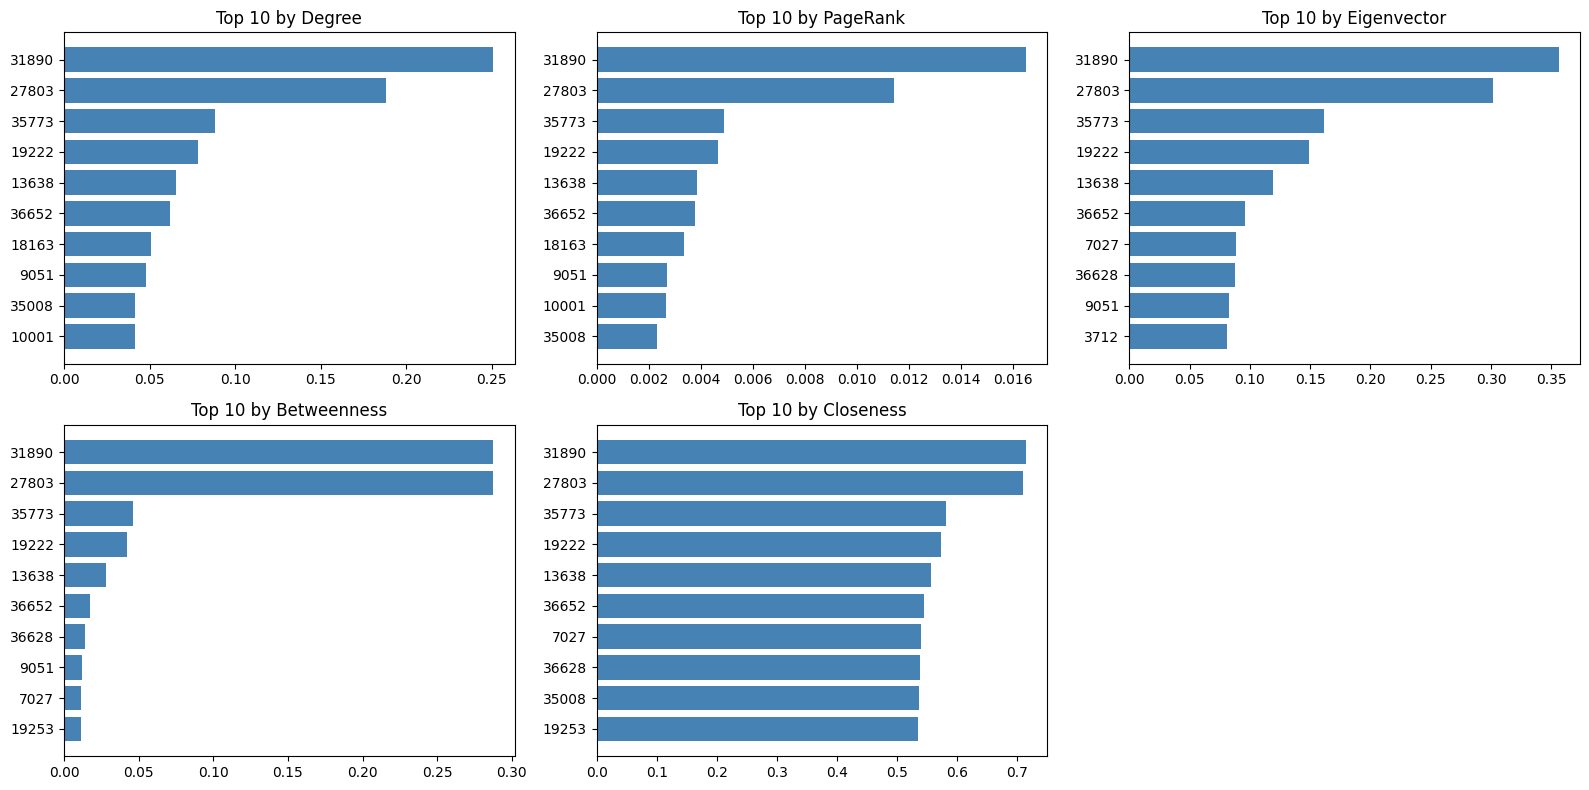

In [126]:
cols = ['Degree', 'PageRank', 'Eigenvector', 'Betweenness', 'Closeness']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), cols):
    t = results_df.nlargest(10, col)
    ax.barh(t["Node"].astype(str), t[col], color="steelblue")
    ax.invert_yaxis(); ax.set_title(f"Top 10 by {col}")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

# **Community Detection & Modularity**

In [129]:
communities = nx_comm.louvain_communities(G, seed=42)
print("Number of communities:", len(communities))
print("Top 5 sizes:", sorted(map(len, communities), reverse=True)[:5])

node_comm = {n: i for i, c in enumerate(communities) for n in c}
centrality_df["Community"] = centrality_df["Node"].map(node_comm)

Number of communities: 33
Top 5 sizes: [7693, 7440, 7436, 5053, 3131]


In [130]:
rows = []
for i, c in enumerate(communities):
    top = max(c, key=lambda n: degree[n])
    rows.append({"Community": i, "Size": len(c),
                 "AvgDegree": np.mean([degree[n] for n in c]),
                 "TopNode": top, "TopNodeDegree": degree[top]})
comm_df = pd.DataFrame(rows).sort_values("Size", ascending=False)
comm_df.head(10)

,Community,Size,AvgDegree,TopNode,TopNodeDegree
12,12,7693,0.000475,31890,0.250882
21,21,7440,0.000323,27803,0.187936
26,26,7436,0.000502,13638,0.065466
14,14,5053,0.000390,35773,0.088172
18,18,3131,0.000447,36652,0.062150
32,32,2467,0.000298,30235,0.011220
3,3,2282,0.000332,5629,0.034908
4,4,533,0.000255,22782,0.007852
7,7,531,0.000304,35822,0.005358
5,5,488,0.000408,15750,0.008303


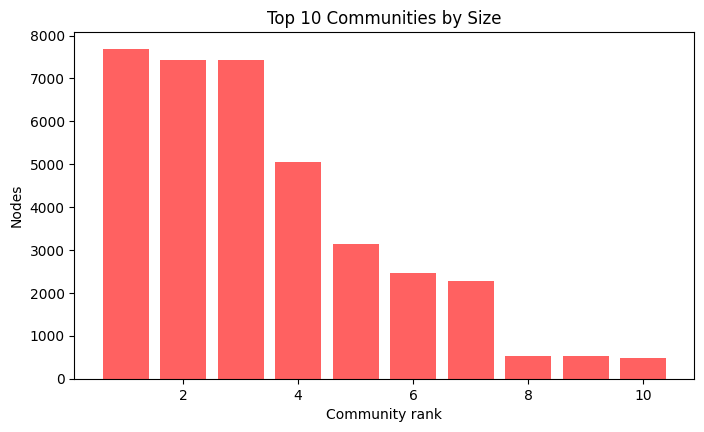

In [131]:
sizes = sorted(map(len, communities), reverse=True)
plt.figure(figsize=(8, 4.5))
plt.bar(range(1, 11), sizes[:10], color="#ff6161")
plt.xlabel("Community rank"); plt.ylabel("Nodes"); plt.title("Top 10 Communities by Size")
plt.show()

In [132]:
lab = target_df.set_index("id")["ml_target"]
nodes = [n for n in G.nodes() if n in lab.index]
nmi = normalized_mutual_info_score([lab[n] for n in nodes], [node_comm[n] for n in nodes])
print(f"NMI vs ml_target: {nmi:.3f}")

NMI vs ml_target: 0.111


In [133]:
Q = nx_comm.modularity(G, communities)
print(f"Modularity: {Q:.4f}")

Modularity: 0.4543


In [160]:
nodes_df = pd.DataFrame({
    "node": list(G.nodes()),
    "community": [node_comm[n] for n in G.nodes()],
    "degree": [degree[n] for n in G.nodes()],
})
edges_c = pd.DataFrame(list(G.edges()), columns=["src", "dst"])

g = (graphistry.edges(edges_c, "src", "dst")
     .nodes(nodes_df, "node")
     .encode_point_color("community", palette=["blue", "red", "green", "orange",
                         "purple", "teal", "pink", "brown"], as_categorical=True)
     .bind(point_size="degree"))
g.plot()
